In [44]:
import pandas as pd
import numpy as np
df = pd.read_csv('train.tsv', sep="\t")

df = df.drop_duplicates()
df.head()

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3
0,0,"и,чё,блядь где этот херой был до этого со свои...","Ну и где этот герой был,со своими доказательст...",Где этот герой был до этого со своими доказате...,"и,где этот герой был до этого со своими доказа..."
1,1,"О, а есть деанон этого петуха?","О, а есть деанон",NaN,NaN
2,2,"херну всякую пишут,из-за этого лайка.долбоебизм.","Чушь всякую пишут, из- за этого лайка.","Ерунду всякую пишут,из-за этого лайка.",NaN
3,3,из за таких пидоров мы и страдаем,из за таких плохих людей мы и страдаем,Из-за таких людей мы и страдаем,из за таких как он мы и страдаем
4,4,гондон путинский он а не артист,"Человек Путина он, а не артист",NaN,NaN


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6948 entries, 0 to 6947
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   index             6948 non-null   int64 
 1   toxic_comment     6948 non-null   object
 2   neutral_comment1  6948 non-null   object
 3   neutral_comment2  3150 non-null   object
 4   neutral_comment3  992 non-null    object
dtypes: int64(1), object(4)
memory usage: 271.5+ KB


In [47]:
import re

In [49]:
def beautify(text):
    text = str(text).lower().strip()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'www\S+', '', text)
    text = re.sub(r"\'s", " ", text)
    text = re.sub('\W', ' ', text)
    text = re.sub('\s+', ' ', text)
    if text == None:
      return ""
    return text

df['toxic_comment'] = df['toxic_comment'].apply(beautify)
df['neutral_comment1'] = df['neutral_comment1'].apply(beautify)
df['neutral_comment2'] = df['neutral_comment2'].apply(beautify)
df['neutral_comment3'] = df['neutral_comment3'].apply(beautify)

In [7]:
df[:5]

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3
0,0,"и,чё,блядь где этот херой был до этого со свои...","ну и где этот герой был,со своими доказательст...",где этот герой был до этого со своими доказате...,"и,где этот герой был до этого со своими доказа..."
1,1,"о, а есть деанон этого петуха?","о, а есть деанон",nan,nan
2,2,"херну всякую пишут,из-за этого лайка.долбоебизм.","чушь всякую пишут, из- за этого лайка.","ерунду всякую пишут,из-за этого лайка.",nan
3,3,из за таких пидоров мы и страдаем,из за таких плохих людей мы и страдаем,из-за таких людей мы и страдаем,из за таких как он мы и страдаем
4,4,гондон путинский он а не артист,"человек путина он, а не артист",nan,nan


Избавимся от аномально коротких или длинных сообещений.
Для этого для начала посмотрим на распределение длины токсичных сообщений

Анализировать в дальнейшем будем именно колонку с токсичными сообщениями, так как остальные - это уже переделанные исходные.

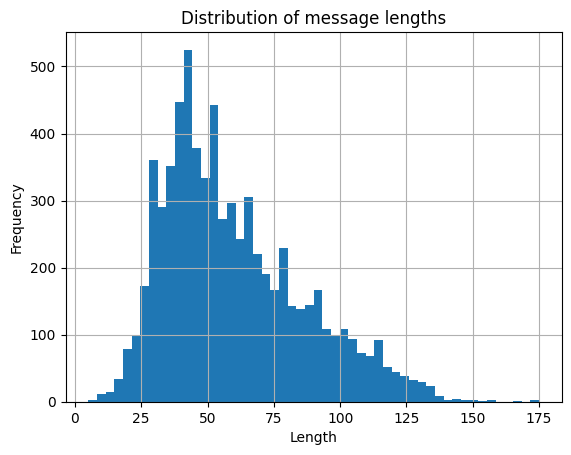

In [50]:
import matplotlib.pyplot as plt


df.apply(lambda x: len(x['toxic_comment']), axis=1).hist(bins=52)
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.title('Distribution of message lengths')
plt.show()

Из графика видно, что разумно почистить например сообщения длины > 130. Коротких сообщений мало, но даже трехбуквенное сообщение может оказаться вполне себе токсичным, так что короткие чистить не будем

In [51]:

df = df[(df['toxic_comment'].apply(lambda x: len(x)) < 130)]
df.shape

(6870, 5)

In [ ]:
df['sentence_count'] = df['toxic_comment'].apply(lambda x: x.count('. '))

In [52]:
import nltk

nltk.download('punkt')
nltk.download('stopwords')

from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


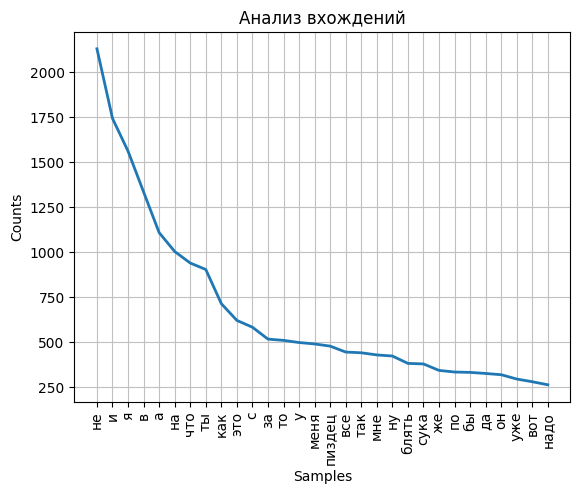

<Axes: title={'center': 'Анализ вхождений'}, xlabel='Samples', ylabel='Counts'>

In [53]:
# Частота вхождений слов
comments = " ".join(clean(df['toxic_comment'].tolist()))


# избавимся от пунктуации в подсчете
tokenizer = nltk.RegexpTokenizer(r'\w+')

tokens = tokenizer.tokenize(comments)
text = nltk.Text(tokens)
dist = FreqDist(text)
dist.plot(30, cumulative=False, title='Анализ вхождений')

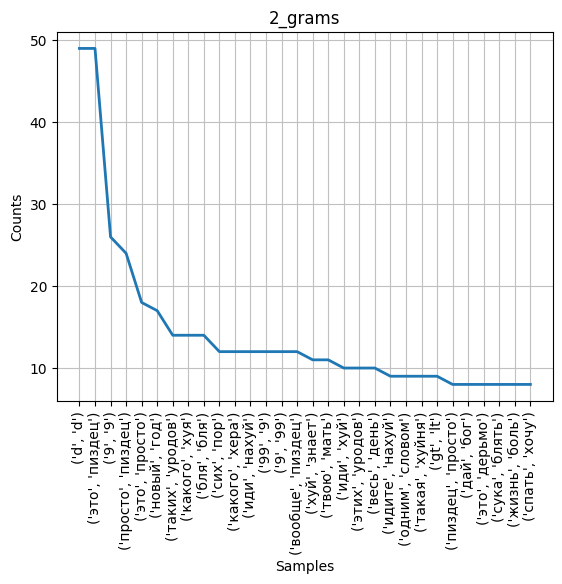

<Axes: title={'center': '2_grams'}, xlabel='Samples', ylabel='Counts'>

In [54]:
from functools import reduce

df['tokenized'] = df['toxic_comment'].apply(lambda x: tokenizer.tokenize(x)).apply(lambda x: [word  for word in x if word not in stopwords.words("russian")])
df['2_grams'] = df['tokenized'].apply(lambda x: list(ngrams(x, 2)))
bigrams = reduce(lambda x, y: x + y, df['2_grams'].values)
dist = FreqDist(bigrams)
dist.plot(30, cumulative=False, title='2_grams')

У нас не безумно большой датасет, поэтому 3-грамм не так уж и много. Это подтверждается и графиком ниже

('блядь', 594)
('сука', 520)
('пиздец', 484)
('такой', 445)
('хотеть', 296)


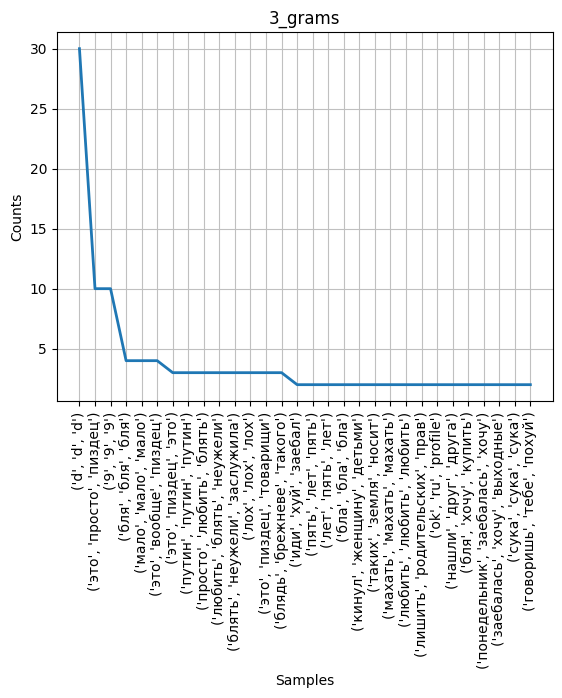

<Axes: title={'center': '3_grams'}, xlabel='Samples', ylabel='Counts'>

In [55]:
df['3_grams'] = df['tokenized'].apply(lambda x: list(ngrams(x, 3)))
threegrams = reduce(lambda x, y: x + y, df['3_grams'].values)
dist = FreqDist(threegrams)
print('\n'.join(map(str, f_dist.most_common(5))))
dist.plot(30, cumulative=False, title='3_grams')

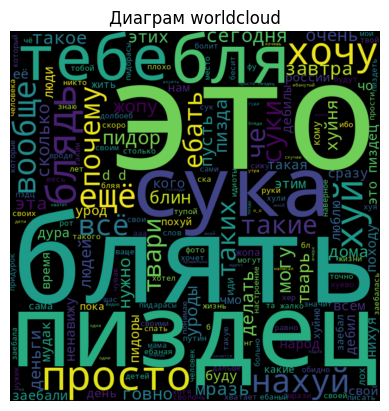

In [56]:
from wordcloud import WordCloud


text1 = [word for word in text if word not in stopwords.words("russian")]
wordcloud_toxic = WordCloud(width=800, height=800, background_color='black').generate(' '.join(text1))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Диаграм worldcloud')
plt.show()

Чтож, вполне ожидаемый результат))

In [33]:
!pip install pymorphy2
import pymorphy2

Посмотрим на стемминг.

('сук', 523)
('пиздец', 484)
('так', 460)
('блят', 386)
('бля', 306)


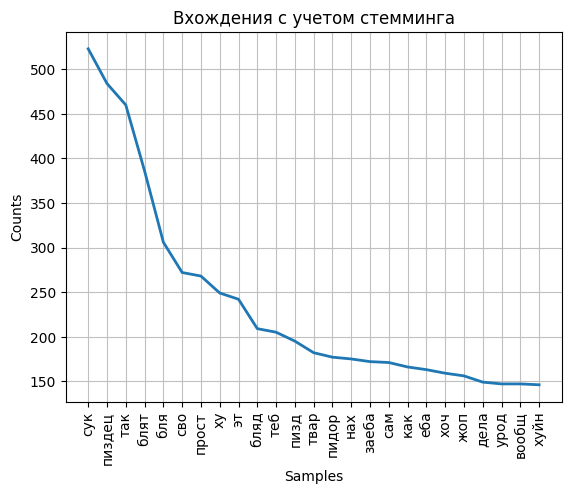

<Axes: title={'center': 'Вхождения с учетом стемминга'}, xlabel='Samples', ylabel='Counts'>

In [38]:

from nltk.stem.snowball import SnowballStemmer


stemmer = SnowballStemmer(language='russian')
stemmed = map(lambda word: stemmer.stem(word), text1)
distr = FreqDist(stemmed)
print('\n'.join(map(str, distr.most_common(5))))
distr.plot(25, cumulative=False, title='Вхождения с учетом стемминга')

In [65]:
# Теперь сохраним предложения с учетом стемминга
df['stemmed_toxic'] = df['toxic_comment'].apply(lambda x: " ".join([stemmer.stem(y) for y in x.split()]))

In [66]:
df.head()

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3,tokenized,2_grams,3_grams,stemmed_toxic
0,0,и чё блядь где этот херой был до этого со свои...,ну и где этот герой был со своими доказательст...,где этот герой был до этого со своими доказате...,и где этот герой был до этого со своими доказа...,"[чё, блядь, херой, своими, доказательствами]","[(чё, блядь), (блядь, херой), (херой, своими),...","[(чё, блядь, херой), (блядь, херой, своими), (...",и че бляд где этот хер был до эт со сво доказа...
1,1,о а есть деанон этого петуха,о а есть деанон,nan,nan,"[деанон, петуха]","[(деанон, петуха)]",[],о а ест деанон эт петух
2,2,херну всякую пишут из за этого лайка долбоебизм,чушь всякую пишут из за этого лайка,ерунду всякую пишут из за этого лайка,nan,"[херну, всякую, пишут, лайка, долбоебизм]","[(херну, всякую), (всякую, пишут), (пишут, лай...","[(херну, всякую, пишут), (всякую, пишут, лайка...",херн всяк пишут из за эт лайк долбоебизм
3,3,из за таких пидоров мы и страдаем,из за таких плохих людей мы и страдаем,из за таких людей мы и страдаем,из за таких как он мы и страдаем,"[таких, пидоров, страдаем]","[(таких, пидоров), (пидоров, страдаем)]","[(таких, пидоров, страдаем)]",из за так пидор мы и страда
4,4,гондон путинский он а не артист,человек путина он а не артист,nan,nan,"[гондон, путинский, артист]","[(гондон, путинский), (путинский, артист)]","[(гондон, путинский, артист)]",гондон путинск он а не артист


А теперь посмотрим на n граммы после применения стемминга.

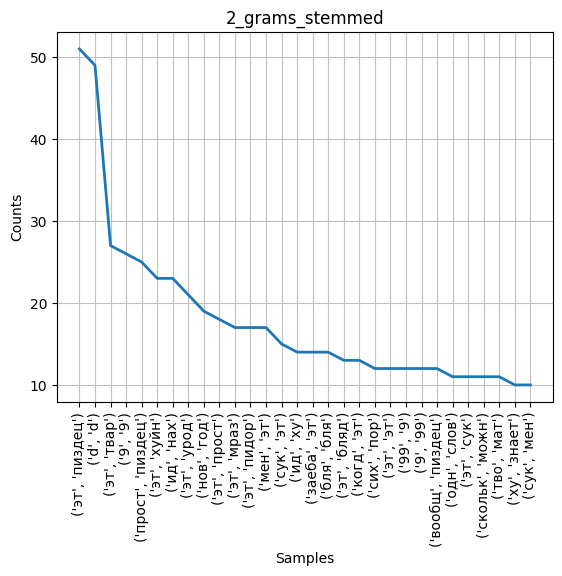

<Axes: title={'center': '2_grams_stemmed'}, xlabel='Samples', ylabel='Counts'>

In [68]:
from functools import reduce

df['tokenized_stemmed'] = df['stemmed_toxic'].apply(lambda x: tokenizer.tokenize(x)).apply(lambda x: [str(word)  for word in x if word not in stopwords.words("russian")])
df['2_grams_stemmed'] = df['tokenized_stemmed'].apply(lambda x: list(ngrams(x, 2)))
bigrams = reduce(lambda x, y: x + y, df['2_grams_stemmed'].values)
dist = FreqDist(bigrams)
dist.plot(30, cumulative=False, title='2_grams_stemmed')

(('d', 'd', 'd'), 30)
(('эт', 'прост', 'пиздец'), 10)
(('9', '9', '9'), 10)
(('ид', 'ху', 'сво'), 4)
(('бля', 'бля', 'бля'), 4)


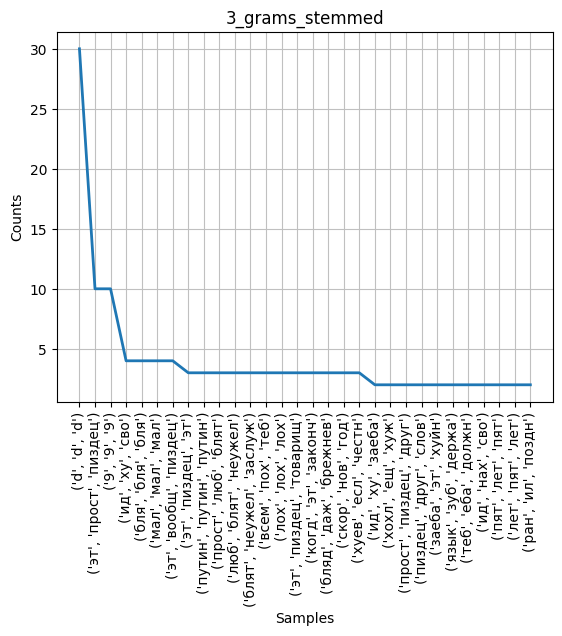

<Axes: title={'center': '3_grams_stemmed'}, xlabel='Samples', ylabel='Counts'>

In [69]:
df['3_grams_stemmed'] = df['tokenized_stemmed'].apply(lambda x: list(ngrams(x, 3)))
threegrams = reduce(lambda x, y: x + y, df['3_grams_stemmed'].values)
dist = FreqDist(threegrams)
print('\n'.join(map(str, dist.most_common(5))))
dist.plot(30, cumulative=False, title='3_grams_stemmed')

In [ ]:
После построения n-грамм с учетом стемминга, видно логично влияние
Пар и троек по смыслу стало больше.

Посмотрим на лемматизацию.

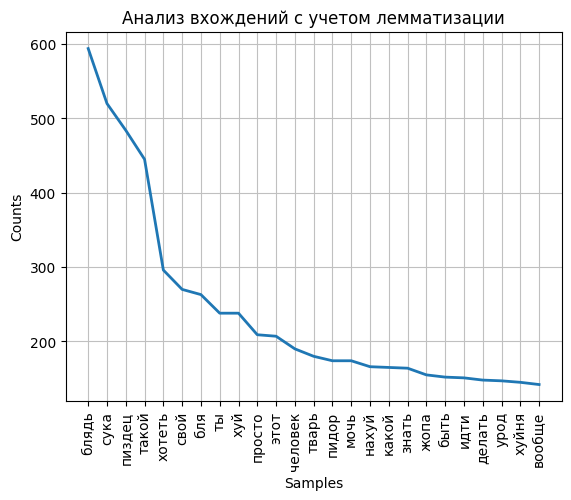

<Axes: title={'center': 'Анализ вхождений с учетом лемматизации'}, xlabel='Samples', ylabel='Counts'>

In [39]:


morph = pymorphy2.MorphAnalyzer()

lemmatized = map(lambda word: morph.parse(word)[0].normal_form, text1)
distr = FreqDist(lemmatized)
distr.plot(25, cumulative=False, title='Анализ вхождений с учетом лемматизации')

**Результат:**
Датасет подходит для дальнейшей работы, как видно из графиков в нем много показательных и плохих слов, которые хорошо приводятся к нормальной форме. Популярные ругательства встречаются сотни раз. У ругательств в основном много общих корней, как видно из проделанных выше процедур.
Данные оказалось не так трудно почистить от пунктуации, тэгов и прочих добавок, мешающих конструктивному анализу.